# Applied Statistics Assignment

### Date: Jun 20, 2020

## Task #1 : Import the necessary libraries 


In [1]:
# importing necessary libraries

import pandas as pd
import numpy as np
import scipy.stats as stats
import statsmodels.stats.proportion as statsmod
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="darkgrid")

## Task#2 : 2. Read the data as a data frame


In [2]:
# Importing the insurance data
insurance_data = pd.read_csv('insurance.csv')

# view dataset structure
insurance_data.head()



,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## Task #3 : Perform basic EDA which should include the following and print out your insights at every step.

In [3]:

insurance_data.shape

(1338, 7)

### 3b. Data types

In [4]:
insurance_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


### 3c. Finding Missing data

In [5]:

null_values = insurance_data.isnull()

## Note: if value_count returns 'True >0' then there exists null value in the data

print(f'Distribution of Null value vs Non-Null values in age: {null_values.age.value_counts()}' )
print(f'Distribution of Null value vs Non-Null values in sex: {null_values.sex.value_counts()}' )
print(f'Distribution of Null value vs Non-Null values in bmi: {null_values.bmi.value_counts()}' )
print(f'Distribution of Null value vs Non-Null values in children: {null_values.children.value_counts()}' )
print(f'Distribution of Null value vs Non-Null values in smoker: {null_values.smoker.value_counts()}' )
print(f'Distribution of Null value vs Non-Null values in region: {null_values.region.value_counts()}' )
print(f'Distribution of Null value vs Non-Null values in charges: {null_values.charges.value_counts()}' )



Distribution of Null value vs Non-Null values in age: False    1338
Name: age, dtype: int64
Distribution of Null value vs Non-Null values in sex: False    1338
Name: sex, dtype: int64
Distribution of Null value vs Non-Null values in bmi: False    1338
Name: bmi, dtype: int64
Distribution of Null value vs Non-Null values in children: False    1338
Name: children, dtype: int64
Distribution of Null value vs Non-Null values in smoker: False    1338
Name: smoker, dtype: int64
Distribution of Null value vs Non-Null values in region: False    1338
Name: region, dtype: int64
Distribution of Null value vs Non-Null values in charges: False    1338
Name: charges, dtype: int64


Observation: Insurance dataset does not have any missing data (Null values)

### 3d. 5-Point summary of numerical data

In [6]:
insurance_data.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


### 3e. Distribution of ‘bmi’, ‘age’ and ‘charges’ columns.


In [21]:
fig, ax = plt.subplots(3,1)
plt.rcParams["figure.figsize"] = [200,100]
fig.suptitle('Data Distributions', fontsize=70)


ax[0].set_xlabel('BMI distribution',fontsize=50)
sns.distplot(insurance_data['bmi'],ax=ax[0])
ax[1].set_xlabel('Age distribution',fontsize=50)
sns.distplot(insurance_data['age'],ax=ax[1])
ax[2].set_xlabel('Charges distribution',fontsize=50)
sns.distplot(insurance_data['charges'],ax=ax[2]);



### 3f. Measure of skewness of ‘bmi’, ‘age’ and ‘charges’ columns

BMI distribute with no skewness<br>
Age seem to be lightly skewed to left<br>
Charges are heavily skewed to the left<br>



### 3g. Checking the presence of outliers in ‘bmi’, ‘age’ and ‘charges


In [22]:

# Making a subplot
fig, ax = plt.subplots(1,3)
plt.rcParams["figure.figsize"] = [100,70]
fig.suptitle('Outlier', fontsize=40)

ax[0].set_xlabel('BMI',fontsize=20)
sns.boxplot(insurance_data['bmi'],ax=ax[0],color='blue',orient='v') 
ax[1].set_xlabel('Age',fontsize=20)
sns.boxplot(insurance_data['age'],ax=ax[1],color='blue',orient='v')
ax[2].set_xlabel('Charges',fontsize=20)
sns.boxplot(insurance_data['charges'],ax=ax[2],color='blue',orient='v');

Observation: 
BMI and Charges both have outlier beyond the 2*IQR range.
<br>
Age does not have any outlier 


### 3h. Distribution of categorical columns (include children)

In [9]:
fig, ax = plt.subplots(2,2)
plt.rcParams["figure.figsize"] = [10,10]

ax[0,0].set_title('Sex',fontsize=60)
sns.countplot(x='sex', data=insurance_data,ax=ax[0,0])
ax[0,1].set_title('Children',fontsize=60)
sns.countplot(x='children', data=insurance_data,ax=ax[0,1])
ax[1,0].set_title('Smoker',fontsize=60)
sns.countplot(x='smoker', data=insurance_data,ax=ax[1,0])
ax[1,1].set_title('Region',fontsize=60)
sns.countplot(x='region', data=insurance_data,ax=ax[1,1]);

### 3i. Pair plot that includes all the columns of the data frame

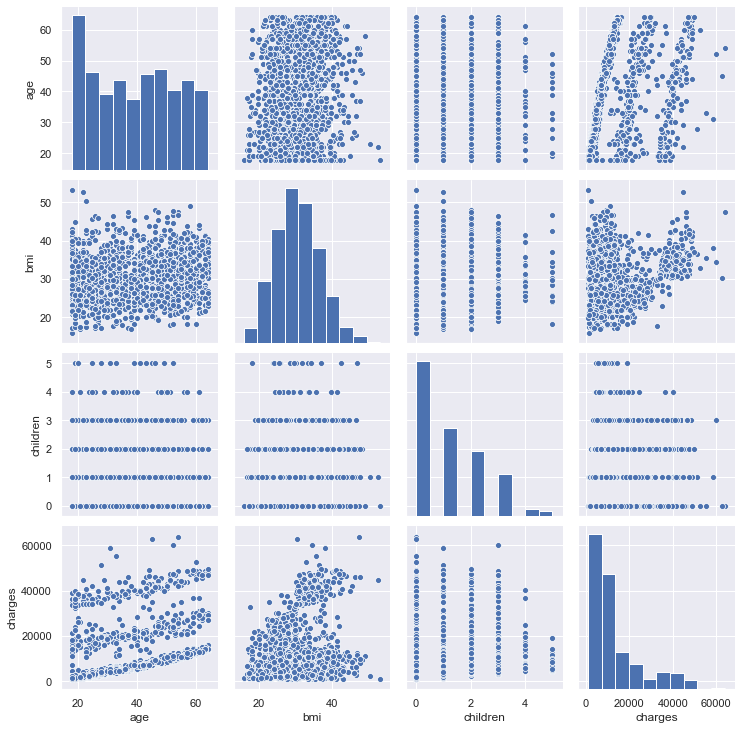

In [10]:


sns.pairplot(insurance_data,kind='scatter');

## Task#4 : Answer the following questions with statistical evidence

### 4a. Do charges of people who smoke differ significantly from the people who don't?

In [12]:


# Filtering the insurance dataset of charges which 'smoker = yes' and 'smoker = no'

charger_smokers = insurance_data.loc[insurance_data.smoker == 'yes', 'charges']
charger_nonsmokers = insurance_data.loc[insurance_data.smoker == 'no', 'charges']

# Null hypothesis (Ho)** : There is no difference between the two means
# Alternate hypothesis (Ha)** : There is significant difference between the two means

alpha = 0.05   # Let's consider a significance level of 5%

t_stats, p_value = stats.ttest_ind(charger_smokers, charger_nonsmokers)
print(f'p-value: {p_value} and t_stat: {t_stats}')

if (p_value<= alpha):
    print(f" As {round(p_value,4)} <= {alpha}, we failed to accept NULL Hypothersis. The difference Charges for smokers and non-smokers is significant")
else:
    print(f"As {round(p_value,4)} > {alpha}, Accept NULL Hypothersis. The difference Charges for smokers and non-smokers difference is not significant")

p-value: 8.271435842177219e-283 and t_stat: 46.664921172723716
 As 0.0 <= 0.05, we failed to accept NULL Hypothersis. The difference Charges for smokers and non-smokers is significant


### 4b. Does bmi of males differ significantly from that of females?

In [13]:


# Filtering the insurance dataset of charges which 'smoker = yes' and 'smoker = no'


bmi_males = insurance_data.loc[insurance_data.sex == 'male', 'bmi']
bmi_females = insurance_data.loc[insurance_data.sex == 'female', 'bmi']


# Null hypothesis (Ho)** : There is no difference between the two means
# Alternate hypothesis (Ha)** : There is significant difference between the two means
alpha = 0.05   # Let's consider a significance level of 5%


t_stats, p_value = stats.ttest_ind(bmi_males, bmi_females)
print(f'p-value: {p_value} and t_stat: {t_stats}')

if (p_value<= alpha):
    print(f" As {round(p_value,3)} <= {alpha}, we failed to accept NULL Hypothersis. The difference BMI for males and females is significant")
else:
    print(f"As {round(p_value,3)} > {alpha}, Accept NULL Hypothersis. The difference BMI for males and females difference is not significant")




p-value: 0.08997637178984932 and t_stat: 1.696752635752224
As 0.09 > 0.05, Accept NULL Hypothersis. The difference BMI for males and females difference is not significant


In [14]:
insurance_data.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


### 4c. Is the proportion of smokers significantly different in different genders?

In [15]:


male_smoker = insurance_data[insurance_data.sex == 'male'].smoker.value_counts()['yes']
female_smoker = insurance_data[insurance_data.sex == 'female'].smoker.value_counts()['yes']

n_male = insurance_data.sex.value_counts()['male']
n_female = insurance_data.sex.value_counts()['female']


# Null hypothesis (Ho) : Ho = The proportions are equal
# Alternate hypothesis (Ha) : The two proportions are not equal
alpha = 0.05   # Let's consider a significance level of 5%

print(f'There are {male_smoker} in {n_male} male in the distribution. There are {female_smoker} in {n_female} male in the distribution.')

t_stats, p_value =t_stats, p_value = statsmod.proportions_ztest([male_smoker,female_smoker], [n_male,n_female])

if (p_value<= alpha):
    print(f" As {round(p_value,3)} <= {alpha}, we failed to accept NULL Hypothersis. The proportions are not equal")
else:
    print(f"As {round(p_value,3)} > {alpha}, Accept NULL Hypothersis. The proportions are equal")



There are 159 in 676 male in the distribution. There are 115 in 662 male in the distribution.
 As 0.005 <= 0.05, we failed to accept NULL Hypothersis. The proportions are not equal


### 4d. Is the distribution of bmi across women with no children, one child and two children, the same?

In [24]:
#Creating a dataframe of BMI means
mean_bmi_df = pd.DataFrame()

mean_bmi_df = mean_bmi_df.append(pd.DataFrame({'C':[0], 'mean':[insurance_data[insurance_data.children == 0].bmi.mean()]}))
mean_bmi_df = mean_bmi_df.append(pd.DataFrame({'C':[1], 'mean':[insurance_data[insurance_data.children == 1].bmi.mean()]}))
mean_bmi_df = mean_bmi_df.append(pd.DataFrame({'C':[2], 'mean':[insurance_data[insurance_data.children == 2].bmi.mean()]}))


n0_child_BMI_mean = insurance_data[insurance_data.children == 0].bmi.mean()
n1_child_BMI_mean = insurance_data[insurance_data.children == 1].bmi.mean()
n2_child_BMI_mean = insurance_data[insurance_data.children == 2].bmi.mean()


mean_bmi_df.head()

,C,mean
0,0,30.550296
0,1,30.623148
0,2,30.978104


In [25]:
import statsmodels.api         as     sm
from   statsmodels.formula.api import ols

# Null hypothesis (Ho) : Ho = All populations have the same mean
# Alternate hypothesis (Ha) : All populations do not have the same mean
alpha = 0.05   # Let's consider a significance level of 5%

mod = ols('mean ~ C', data = mean_bmi_df).fit()
aov_table = sm.stats.anova_lm(mod, typ=2)
print(aov_table)







sum_sq   df         F    PR(>F)
C         0.091510  1.0  6.899227  0.231584
Residual  0.013264  1.0       NaN       NaN


In [18]:
if (p_value<= alpha):
    print(f" As {round(0.231584,3)} <= {alpha}, we failed to accept NULL Hypothersis. The proportions are not equal")
else:
    print(f"As {round(0.231584,3)} > {alpha}, Accept NULL Hypothersis. The proportions are equal")

As 0.232 <= 0.05, we failed to accept NULL Hypothersis. The proportions are not equal
